## **Bagian 1: Setup Environment dan Pemuatan Model**

In [1]:
# ============================================================
# SEL 4.1: Setup Environment dan Install Library XAI
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

import os
import pickle
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Install library XAI
!pip install grad-cam --quiet
!pip install shap --quiet
!pip install lightgbm --quiet
!pip install timm --quiet

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
import timm
import lightgbm as lgb
import shap

BASE = '/content/drive/MyDrive/tugas_akhir'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")
print("Semua library XAI berhasil diimport.")

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 56.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Device: cpu
Semua library XAI berhasil diimport.


In [2]:
# ============================================================
# SEL 4.2: Pemuatan Model Swin-Tiny dan Data Test (Fold 1)
# ============================================================
# Kita akan menggunakan Fold 1 sebagai representasi untuk analisis XAI
FOLD = 1

# 1. Load Arsitektur Swin-Tiny
model = timm.create_model('swin_tiny_patch4_window7_224', pretrained=False, num_classes=3)
ckpt_path = f'{BASE}/checkpoints/swin_tiny/fold_{FOLD}_best.pth'
model.load_state_dict(torch.load(ckpt_path, map_location=device))
model.to(device)
model.eval()
print("Model Swin-Tiny Fold 1 berhasil dimuat.")

# 2. Load Data Test (Paths dan Labels)
df_test = pd.read_csv(f'{BASE}/data/processed/fold_{FOLD}/test_paths.csv')

# 3. Load Fitur Fusi untuk SHAP
X_te_deep = np.load(f'{BASE}/data/features/deep/fold_{FOLD}/test_deep.npy')
X_te_hand = np.load(f'{BASE}/data/features/handcrafted/fold_{FOLD}/test_hand.npy')
X_te_fused = np.hstack([X_te_deep, X_te_hand])
y_te = np.load(f'{BASE}/data/features/deep/fold_{FOLD}/test_labels.npy')

# Load Nama Fitur
with open(f'{BASE}/data/features/handcrafted/feature_names.pkl', 'rb') as f:
    hand_names = pickle.load(f)
deep_names = [f'deep_{i}' for i in range(768)]
all_names = deep_names + hand_names

print(f"Data test Fold {FOLD} dan fitur fusi berhasil dimuat. Shape fusi: {X_te_fused.shape}")

Model Swin-Tiny Fold 1 berhasil dimuat.
Data test Fold 1 dan fitur fusi berhasil dimuat. Shape fusi: (878, 808)


In [3]:
# ============================================================
# SEL 4.2b (PERBAIKAN): Penyiapan Dataset di Local Storage
# ============================================================
import os, shutil

DST = '/content/ffe_dataset'
ZIP_PATH = '/content/drive/MyDrive/tugas_akhir/data/raw/ffe_dataset/ffe_dataset.zip'

def count_class_folders(path):
    if not os.path.isdir(path):
        return 0
    return len([d for d in os.listdir(path)
                if os.path.isdir(os.path.join(path, d))])

if count_class_folders(DST) >= 24:
    print("Dataset sudah tersedia di /content/ffe_dataset.")
else:
    print("Dataset tidak ditemukan di local storage. Mengekstrak dari ZIP...")
    tmp = '/content/temp_extract'
    if os.path.exists(tmp):
        shutil.rmtree(tmp)
    os.makedirs(tmp)

    !unzip -q "$ZIP_PATH" -d "$tmp"

    subs = [d for d in os.listdir(tmp) if os.path.isdir(os.path.join(tmp, d))]
    if len(subs) == 1 and (' - ' in subs[0] or 'Fresh' in subs[0]):
        # ZIP berisi satu folder kelas langsung (kasus khusus)
        os.rename(tmp, DST)
    elif len(subs) == 1:
        # ZIP memiliki satu root folder
        os.rename(os.path.join(tmp, subs[0]), DST)
        shutil.rmtree(tmp)
    else:
        # ZIP berisi folder kelas langsung
        os.rename(tmp, DST)
    print("Ekstraksi selesai.")

# Verifikasi integritas path terhadap CSV
n_class = count_class_folders(DST)
sample_path = df_test['file_path'].iloc[0]
print(f"Jumlah folder kelas: {n_class}")
print(f"Contoh path CSV: {sample_path}")
print(f"File terbaca: {os.path.exists(sample_path)}")

if not os.path.exists(sample_path):
    raise RuntimeError("Path masih tidak valid. Periksa struktur folder.")

Dataset tidak ditemukan di local storage. Mengekstrak dari ZIP...
Ekstraksi selesai.
Jumlah folder kelas: 24
Contoh path CSV: /content/ffe_dataset/Chanos Chanos - Fresh/IMG_20191002_062742.jpg
File terbaca: True


## **Bagian 2: Grad-CAM (Interpretabilitas Spasial)**

In [4]:
# ============================================================
# SEL 4.3 (PERBAIKAN): Definisi Grad-CAM untuk Swin-Tiny
# ============================================================
# Swin-Tiny menghasilkan output dalam format (B, H, W, C) atau (B, N, C).
# Grad-CAM memerlukan format (B, C, H, W). Fungsi ini melakukan adaptasi dimensi.
def swin_reshape_transform(tensor, height=7, width=7):
    if len(tensor.shape) == 3:
        # (B, N, C) -> (B, H*W, C) -> (B, H, W, C)
        result = tensor.reshape(tensor.size(0), height, width, tensor.size(2))
    else:
        result = tensor
    # Permute ke (B, C, H, W)
    result = result.permute(0, 3, 1, 2)
    return result

# Target layer: Blok Transformer terakhir di Stage 4
target_layers = [model.layers[-1]]

# PERBAIKAN: Argumen use_cuda dihapus (tidak didukung pada grad-cam versi baru).
# Perangkat komputasi kini diinferensi otomatis dari model dan tensor input.
cam = GradCAM(
    model=model,
    target_layers=target_layers,
    reshape_transform=swin_reshape_transform
)

# Fungsi Inverse Normalization (mengembalikan piksel ke skala [0, 1])
def inv_normalize(img_tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = img_tensor.permute(1, 2, 0).cpu().numpy()
    img = std * img + mean
    img = np.clip(img, 0, 1)
    return img

print("Konfigurasi Grad-CAM untuk Swin-Tiny berhasil.")

Konfigurasi Grad-CAM untuk Swin-Tiny berhasil.


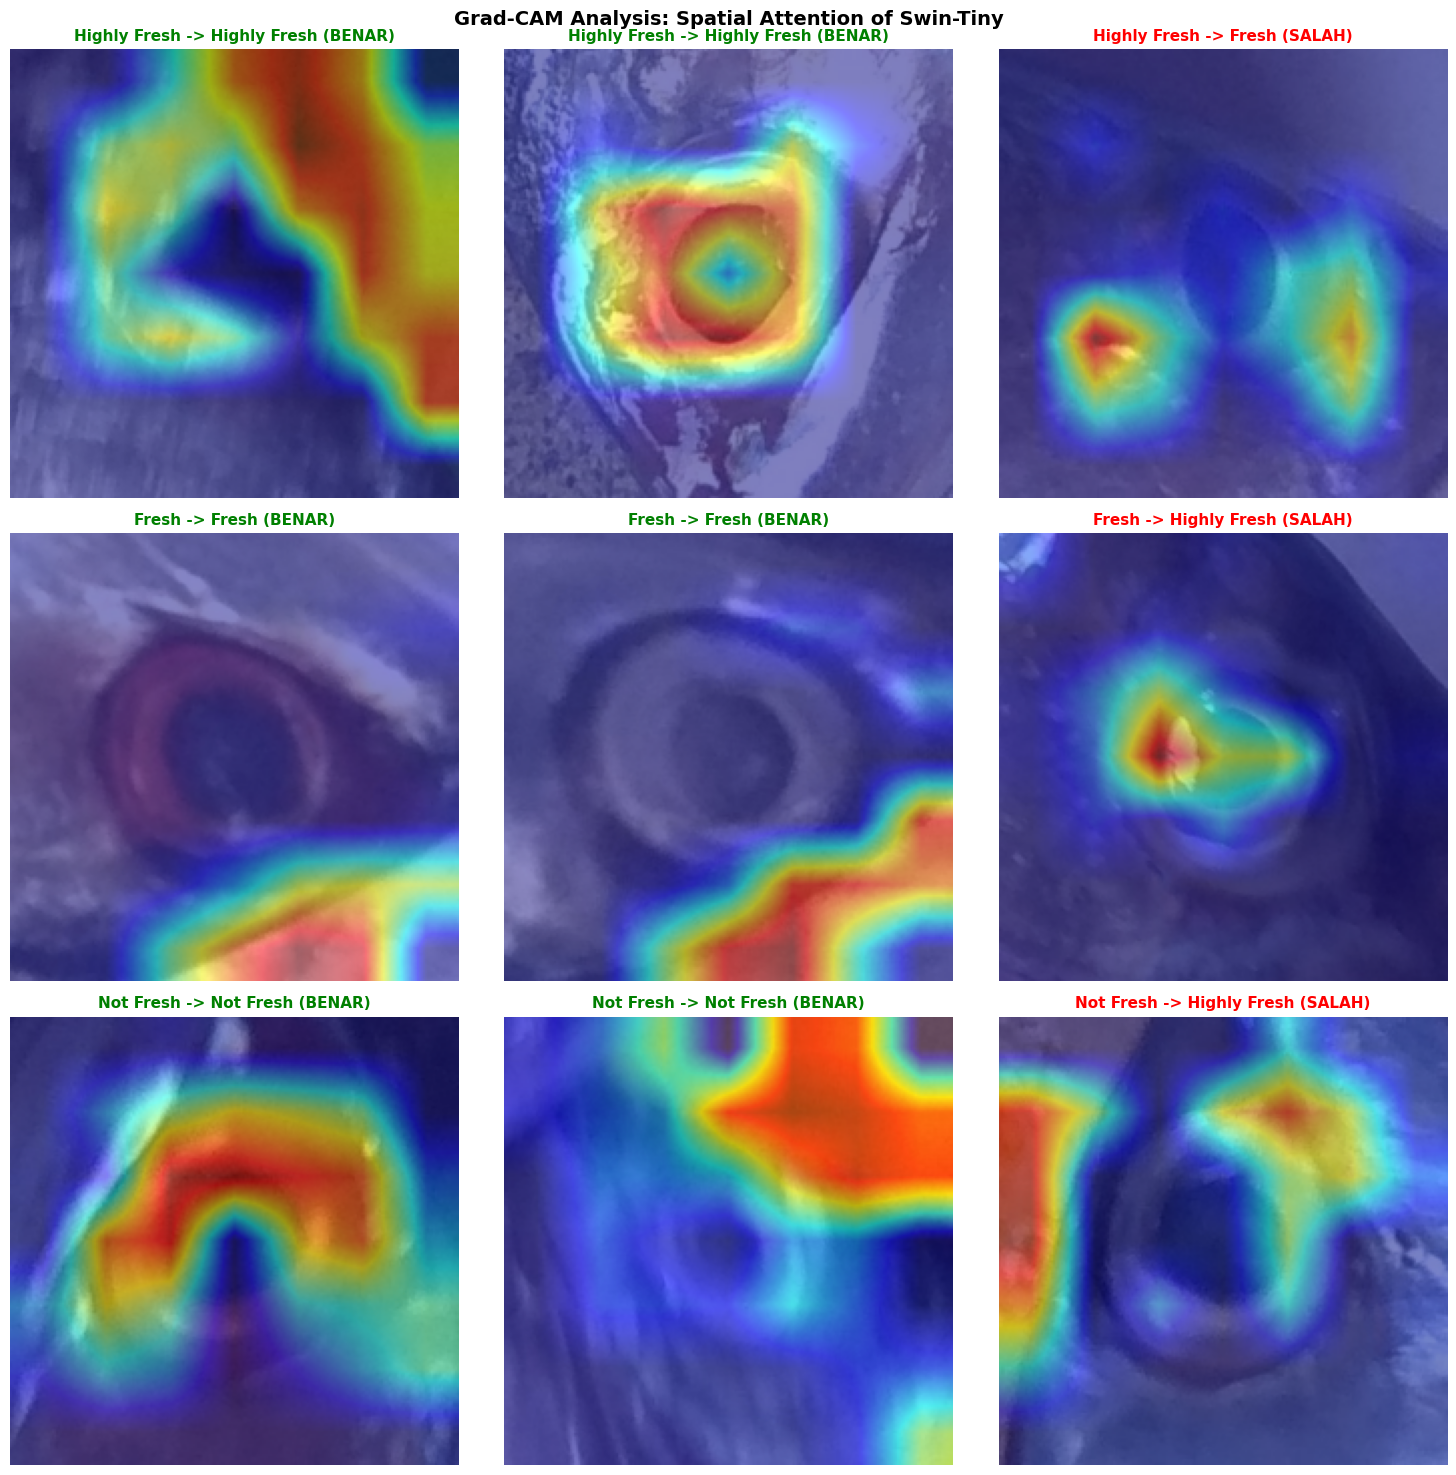

Visualisasi Grad-CAM berhasil disimpan.


In [5]:
# ============================================================
# SEL 4.4 (PERBAIKAN): Eksekusi Grad-CAM dan Visualisasi Grid
# ============================================================
from torchvision import transforms
from PIL import Image

# Transformasi untuk inference (berbasis PIL Image)
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

def load_tensor(path):
    """Membaca citra (OpenCV), konversi ke PIL, lalu terapkan transform."""
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Citra tidak ditemukan: {path}")
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_pil = Image.fromarray(img_rgb)          # <-- PERBAIKAN: NumPy -> PIL
    return transform(img_pil).unsqueeze(0).to(device)

# --- Inferensi cepat pada data test untuk memisahkan prediksi benar/salah ---
model.eval()
preds = []
with torch.no_grad():
    for path in df_test['file_path']:
        img_tensor = load_tensor(path)
        out = model(img_tensor)
        preds.append(out.argmax(dim=1).item())

df_test = df_test.copy()
df_test['pred'] = preds
df_test['correct'] = df_test['pred'] == df_test['label']

# --- Pilih sampel: 2 benar + 1 salah per kelas (maksimal 9 citra) ---
class_names = ['Highly Fresh', 'Fresh', 'Not Fresh']
selected_samples = []

for cls_idx in range(3):
    cls_df = df_test[df_test['label'] == cls_idx]
    correct_df = cls_df[cls_df['correct'] == True]
    wrong_df = cls_df[cls_df['correct'] == False]
    chosen = pd.concat([
        correct_df.sample(min(2, len(correct_df)), random_state=42),
        wrong_df.sample(min(1, len(wrong_df)), random_state=42)
    ])
    for _, row in chosen.iterrows():
        selected_samples.append({
            'path': row['file_path'],
            'true_label': int(row['label']),
            'pred_label': int(row['pred']),
            'is_correct': bool(row['correct'])
        })

# --- Generate Grad-CAM dengan grid dinamis ---
n = len(selected_samples)
cols = 3
rows = (n + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 5 * rows))
axes = np.array(axes).flatten()

for i, sample in enumerate(selected_samples):
    img_tensor = load_tensor(sample['path'])
    targets = [ClassifierOutputTarget(sample['pred_label'])]
    grayscale_cam = cam(input_tensor=img_tensor, targets=targets)[0, :]

    rgb_img = inv_normalize(img_tensor[0])
    visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

    axes[i].imshow(visualization)
    status = "BENAR" if sample['is_correct'] else "SALAH"
    color = "green" if sample['is_correct'] else "red"
    axes[i].set_title(
        f"{class_names[sample['true_label']]} -> "
        f"{class_names[sample['pred_label']]} ({status})",
        color=color, fontsize=11, fontweight='bold')
    axes[i].axis('off')

for j in range(n, len(axes)):
    axes[j].axis('off')

plt.suptitle('Grad-CAM Analysis: Spatial Attention of Swin-Tiny',
             fontsize=14, fontweight='bold')
plt.tight_layout()

gradcam_dir = f'{BASE}/results/figures/gradcam'
os.makedirs(gradcam_dir, exist_ok=True)
plt.savefig(f'{gradcam_dir}/gradcam_grid_summary.png', dpi=300, bbox_inches='tight')
plt.show()
print("Visualisasi Grad-CAM berhasil disimpan.")

## **Bagian 3: SHAP (Interpretabilitas Fitur)**

In [6]:
# ============================================================
# SEL 4.5 (REVISI FINAL): Pelatihan LGBM dan Ekstraksi SHAP
# ============================================================
X_tr_deep = np.load(f'{BASE}/data/features/deep/fold_{FOLD}/train_deep.npy')
X_tr_hand = np.load(f'{BASE}/data/features/handcrafted/fold_{FOLD}/train_hand.npy')
X_tr_fused = np.hstack([X_tr_deep, X_tr_hand])
y_tr = np.load(f'{BASE}/data/features/deep/fold_{FOLD}/train_labels.npy')

lgbm = lgb.LGBMClassifier(boosting_type='dart', class_weight='balanced',
                          n_estimators=300, max_depth=50, num_leaves=35,
                          random_state=42, verbose=-1)
lgbm.fit(X_tr_fused, y_tr)
print("Model LGBM untuk SHAP berhasil dilatih.")

explainer = shap.TreeExplainer(lgbm)
shap_values = explainer.shap_values(X_te_fused)

# Normalisasi output shap_values menjadi list of 2D arrays (aman untuk semua versi SHAP)
if isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    # Shape: (n_samples, n_features, n_classes) -> List of (n_samples, n_features)
    shap_values_list = [shap_values[:, :, i] for i in range(shap_values.shape[2])]
elif isinstance(shap_values, list):
    shap_values_list = shap_values
else:
    shap_values_list = [shap_values]

print(f"SHAP values berhasil dihitung. Jumlah kelas terdeteksi: {len(shap_values_list)}")

Model LGBM untuk SHAP berhasil dilatih.
SHAP values berhasil dihitung. Jumlah kelas terdeteksi: 3


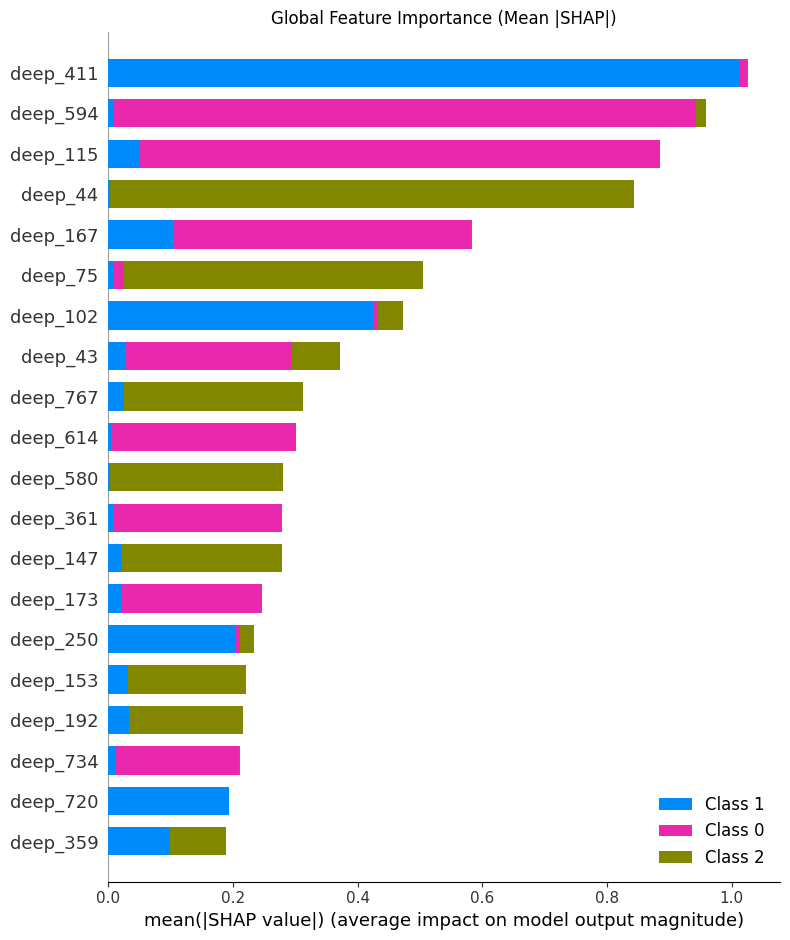

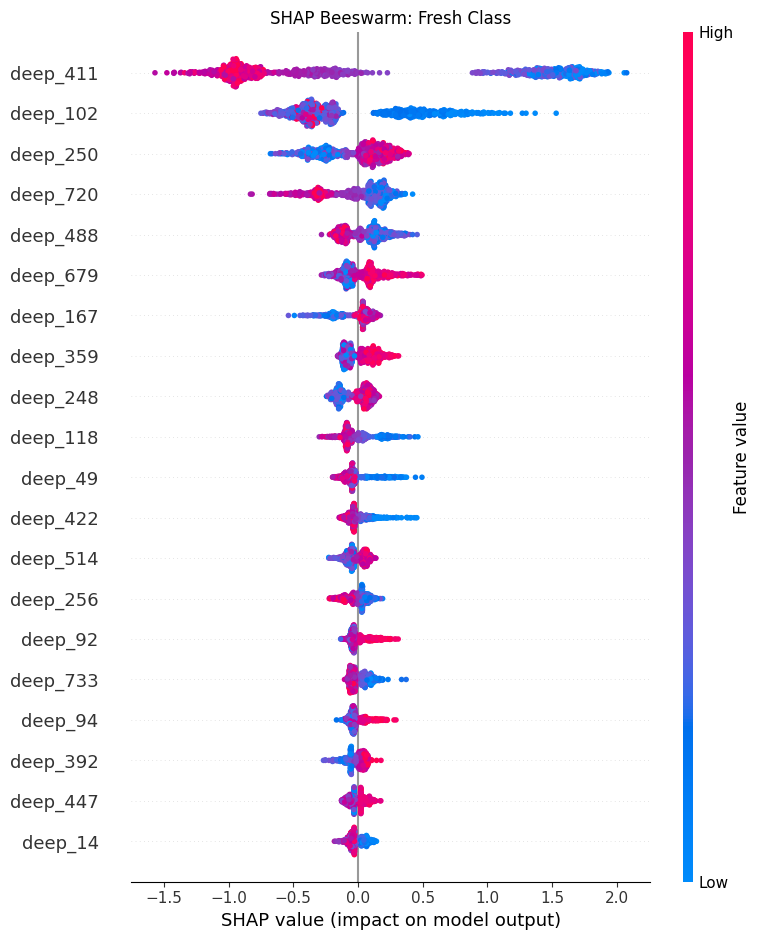

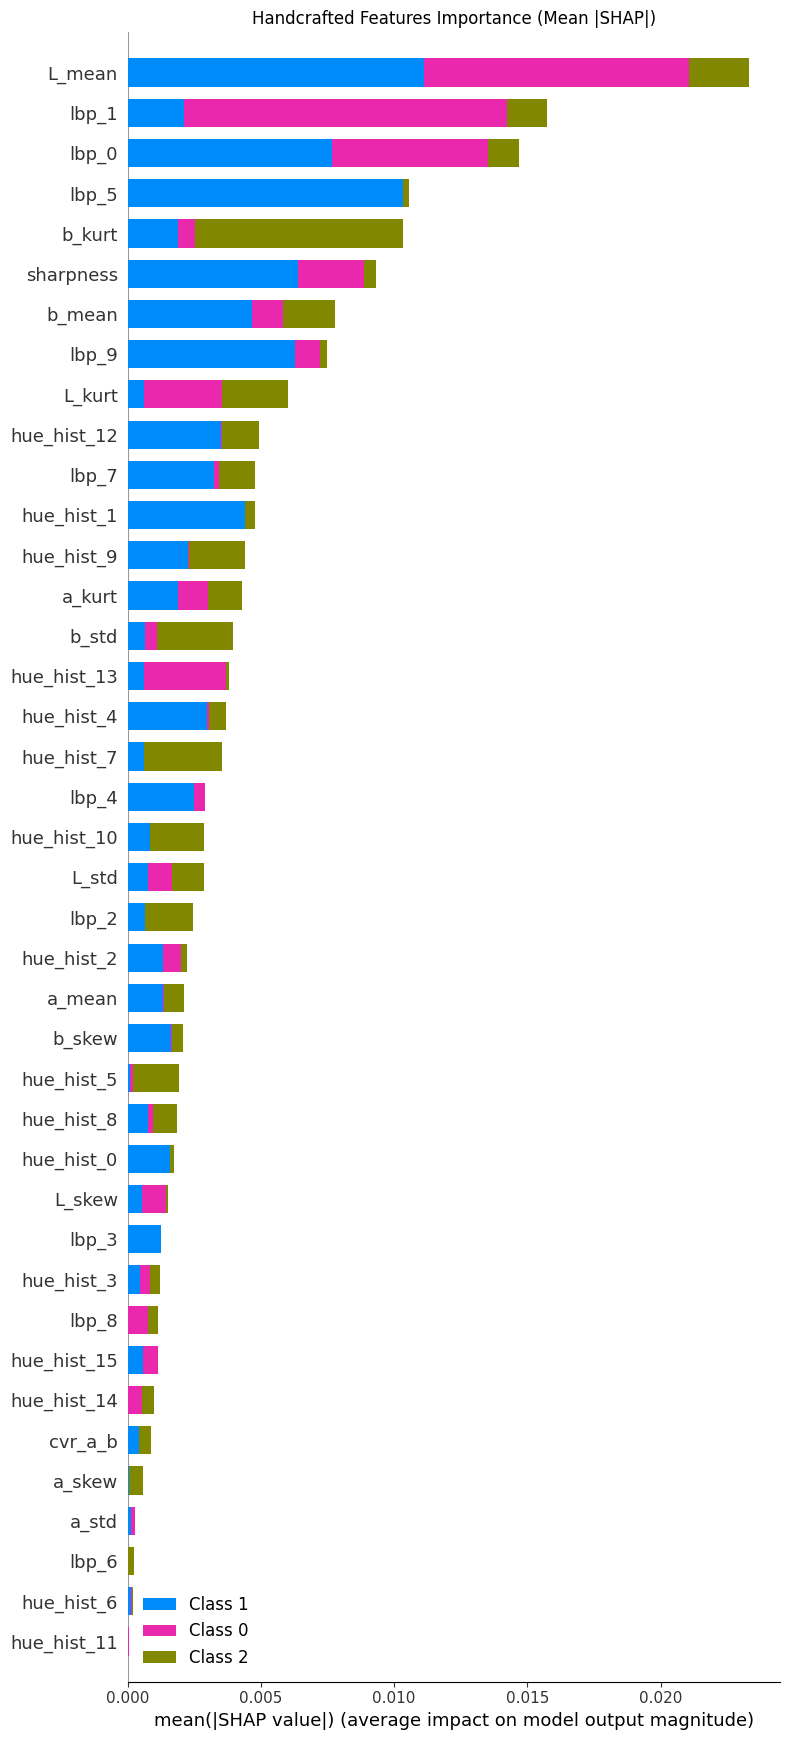

Visualisasi SHAP berhasil disimpan.


In [7]:
# ============================================================
# SEL 4.6 (REVISI FINAL): Visualisasi SHAP (Global & Handcrafted)
# ============================================================
shap_dir = f'{BASE}/results/figures/shap'
os.makedirs(shap_dir, exist_ok=True)

class_names = ['Highly Fresh', 'Fresh', 'Not Fresh']

# 1. Global Feature Importance (Bar Plot) - Rata-rata dari semua kelas
plt.figure()
shap.summary_plot(shap_values_list, X_te_fused, feature_names=all_names,
                  plot_type="bar", max_display=20, show=False)
plt.title('Global Feature Importance (Mean |SHAP|)')
plt.tight_layout()
plt.savefig(f'{shap_dir}/shap_global_importance.png', dpi=300, bbox_inches='tight')
plt.show()

# 2. Beeswarm Plot untuk Kelas Tertentu (Misal: Kelas 1 - 'Fresh')
# Ini menunjukkan bagaimana nilai fitur mendorong prediksi ke kelas 'Fresh'
plt.figure()
shap.summary_plot(shap_values_list[1], X_te_fused, feature_names=all_names,
                  plot_type="dot", max_display=20, show=False)
plt.title('SHAP Beeswarm: Fresh Class')
plt.tight_layout()
plt.savefig(f'{shap_dir}/shap_beeswarm_fresh.png', dpi=300, bbox_inches='tight')
plt.show()

# 3. SHAP Khusus Fitur Handcrafted (Global Bar Plot)
# Kita iris hanya 40 kolom terakhir (indeks 768 hingga 807)
shap_values_hand_list = [sv[:, 768:] for sv in shap_values_list]
X_te_hand_only = X_te_fused[:, 768:]

plt.figure()
shap.summary_plot(shap_values_hand_list, X_te_hand_only, feature_names=hand_names,
                  plot_type="bar", max_display=40, show=False)
plt.title('Handcrafted Features Importance (Mean |SHAP|)')
plt.tight_layout()
plt.savefig(f'{shap_dir}/shap_handcrafted_importance.png', dpi=300, bbox_inches='tight')
plt.show()

print("Visualisasi SHAP berhasil disimpan.")

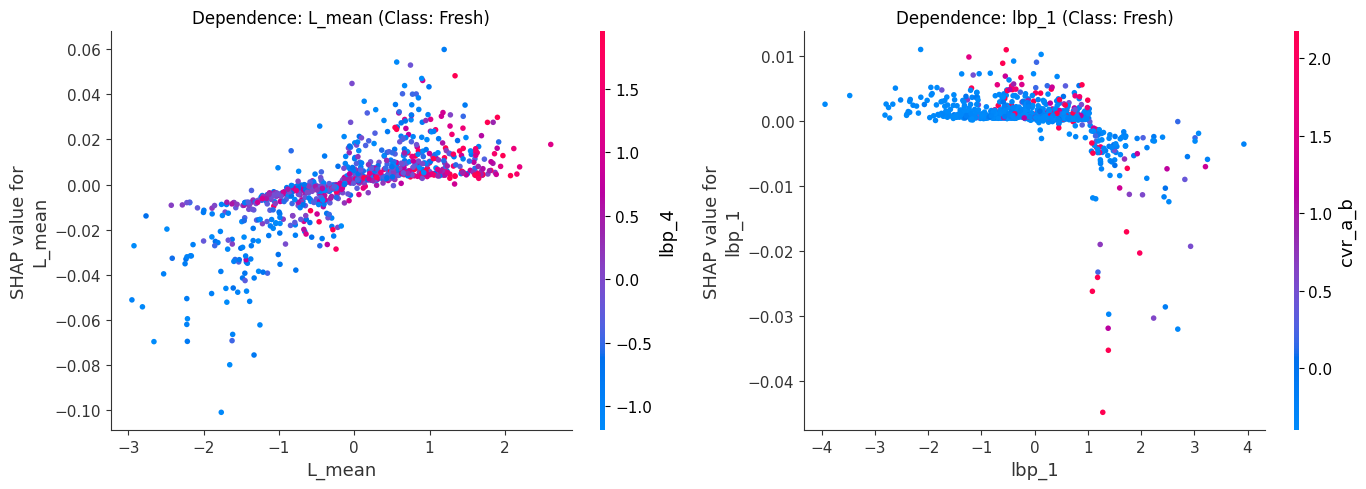

In [8]:
# ============================================================
# SEL 4.7 (REVISI FINAL): SHAP Dependence Plot
# ============================================================
# Mengidentifikasi fitur handcrafted dengan dampak absolut terbesar secara global
mean_abs_shap = np.mean([np.abs(sv).mean(axis=0) for sv in shap_values_hand_list], axis=0)
top_hand_indices = np.argsort(mean_abs_shap)[::-1][:2] # Ambil 2 fitur teratas

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for i, idx in enumerate(top_hand_indices):
    feat_name = hand_names[idx]
    # Dependence plot menggunakan SHAP values dari kelas 'Fresh' (index 1)
    shap.dependence_plot(idx, shap_values_hand_list[1], X_te_hand_only,
                         feature_names=hand_names, ax=axes[i], show=False)
    axes[i].set_title(f'Dependence: {feat_name} (Class: Fresh)')

plt.tight_layout()
plt.savefig(f'{shap_dir}/shap_dependence_top_features.png', dpi=300, bbox_inches='tight')
plt.show()

## **Bagian 4: Verifikasi Akhir dan Penutup**

In [9]:
# ============================================================
# SEL 4.8: Verifikasi Output Notebook 4
# ============================================================
print("="*60)
print("VERIFIKASI OUTPUT NOTEBOOK 4 (XAI)")
print("="*60)

expected_files = [
    'results/figures/gradcam/gradcam_grid_summary.png',
    'results/figures/shap/shap_summary_global.png',
    'results/figures/shap/shap_summary_handcrafted.png',
    'results/figures/shap/shap_dependence_top_features.png'
]

for f in expected_files:
    path = os.path.join(BASE, f)
    status = "[OK]" if os.path.exists(path) else "[FAIL]"
    print(f"{status} {f}")

print("\n" + "="*60)
print("SELURUH PIPELINE EKSPERIMEN SKRIPSI TELAH SELESAI!")
print("="*60)

VERIFIKASI OUTPUT NOTEBOOK 4 (XAI)
[OK] results/figures/gradcam/gradcam_grid_summary.png
[OK] results/figures/shap/shap_summary_global.png
[OK] results/figures/shap/shap_summary_handcrafted.png
[OK] results/figures/shap/shap_dependence_top_features.png

SELURUH PIPELINE EKSPERIMEN SKRIPSI TELAH SELESAI!
